Tugas 1 - kNN untuk klasifikasi suara male/female + pemilihan fitur & nilai k.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("knn_voice.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js09-klasifikasi\tugas-1


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_selection import f_classif
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

HERE = Path(__file__).resolve().parent
ROOT = HERE.parent
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)

df = pd.read_csv(ROOT / "data" / "voice.csv")
print("=== Data voice.csv ===", df.shape)
print(df["label"].value_counts())

X = df.drop(columns="label")
y = (df["label"] == "male").astype(int)   # male=1, female=0
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

=== Data voice.csv === (3168, 21)
label
male      1584
female    1584
Name: count, dtype: int64


In [3]:
# Soal 2 - peringkat fitur dengan ANOVA F, lalu uji set fitur kumulatif (kNN k=5)
F, p = f_classif(X_train_s, y_train)
rank = pd.Series(F, index=X.columns).sort_values(ascending=False)
print("\n=== Peringkat fitur (ANOVA F) ===")
print(rank.round(2).to_string())
rank.to_csv(OUT / "peringkat_fitur.csv")

print("\n=== Akurasi CV per jumlah fitur teratas (k=5) ===")
rows = []
for n in range(2, len(rank) + 1, 2):
    cols = list(rank.index[:n])
    idx = [X.columns.get_loc(c) for c in cols]
    acc = cross_val_score(KNeighborsClassifier(n_neighbors=5), X_train_s[:, idx],
                          y_train, cv=cv).mean()
    rows.append((n, acc))
    print(f"{n:2d} fitur: {acc:.4f}")
# tambahkan konfigurasi seluruh fitur
acc_all = cross_val_score(KNeighborsClassifier(n_neighbors=5), X_train_s,
                          y_train, cv=cv).mean()
rows.append((len(rank), acc_all))
print(f"{len(rank):2d} fitur (semua): {acc_all:.4f}")

best_n, best_cv = max(rows, key=lambda r: r[1])
best_cols = list(rank.index[:best_n])
print(f"\nJumlah fitur terbaik: {best_n} (CV acc={best_cv:.4f})")
print("Fitur terpilih:", best_cols)


=== Peringkat fitur (ANOVA F) ===
meanfun     5697.87
IQR         1566.49
Q25          890.39
sp.ent       794.11
sd           750.76
sfm          375.21
centroid     324.44
meanfreq     324.44
median       218.28
mindom       100.41
maxdom        96.54
dfrange       93.04
meandom       89.24
mode          76.08
maxfun        69.67
minfun        47.37
kurt          19.33
Q75           11.31
skew           3.81
modindx        2.11

=== Akurasi CV per jumlah fitur teratas (k=5) ===
 2 fitur: 0.9680


 4 fitur: 0.9724
 6 fitur: 0.9799


 8 fitur: 0.9799
10 fitur: 0.9771


12 fitur: 0.9740
14 fitur: 0.9720


16 fitur: 0.9732
18 fitur: 0.9736
20 fitur: 0.9700
20 fitur (semua): 0.9700

Jumlah fitur terbaik: 6 (CV acc=0.9799)
Fitur terpilih: ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm']


In [4]:
# Soal 3 - sweep nilai k pada set fitur terbaik, evaluasi train/test + CV
idx = [X.columns.get_loc(c) for c in best_cols]
Xtr, Xte = X_train_s[:, idx], X_test_s[:, idx]
print("\n=== Nilai k vs akurasi (fitur terpilih) ===")
print(" k | acc_train | acc_test | acc_cv")
res = []
for k in range(1, 31, 2):
    model = KNeighborsClassifier(n_neighbors=k).fit(Xtr, y_train)
    a_tr = model.score(Xtr, y_train)
    a_te = model.score(Xte, y_test)
    a_cv = cross_val_score(KNeighborsClassifier(n_neighbors=k), Xtr, y_train,
                           cv=cv).mean()
    res.append((k, a_tr, a_te, a_cv))
    print(f"{k:2d} | {a_tr:9.4f} | {a_te:.4f} | {a_cv:.4f}")

pd.DataFrame(res, columns=["k", "acc_train", "acc_test", "acc_cv"]).to_csv(
    OUT / "akurasi_per_k.csv", index=False)

best_k = max(res, key=lambda r: r[3])[0]
knn = KNeighborsClassifier(n_neighbors=best_k).fit(Xtr, y_train)
y_pred = knn.predict(Xte)
print(f"\n=== Evaluasi akhir: {best_n} fitur, k={best_k} ===")
print("Akurasi test:", accuracy_score(y_test, y_pred))
print("Confusion Matrix (female, male):\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["female", "male"],
                            digits=4))


=== Nilai k vs akurasi (fitur terpilih) ===
 k | acc_train | acc_test | acc_cv


 1 |    1.0000 | 0.9858 | 0.9728


 3 |    0.9862 | 0.9874 | 0.9814


 5 |    0.9834 | 0.9858 | 0.9799


 7 |    0.9826 | 0.9811 | 0.9783


...

21 |    0.9724 | 0.9763 | 0.9696


23 |    0.9720 | 0.9763 | 0.9688


25 |    0.9704 | 0.9732 | 0.9676


27 |    0.9700 | 0.9732 | 0.9661


29 |    0.9704 | 0.9732 | 0.9657

=== Evaluasi akhir: 6 fitur, k=3 ===
Akurasi test: 0.9873817034700315
Confusion Matrix (female, male):
 [[313   4]
 [  4 313]]
              precision    recall  f1-score   support

      female     0.9874    0.9874    0.9874       317
        male     0.9874    0.9874    0.9874       317

    accuracy                         0.9874       634
   macro avg     0.9874    0.9874    0.9874       634
weighted avg     0.9874    0.9874    0.9874       634



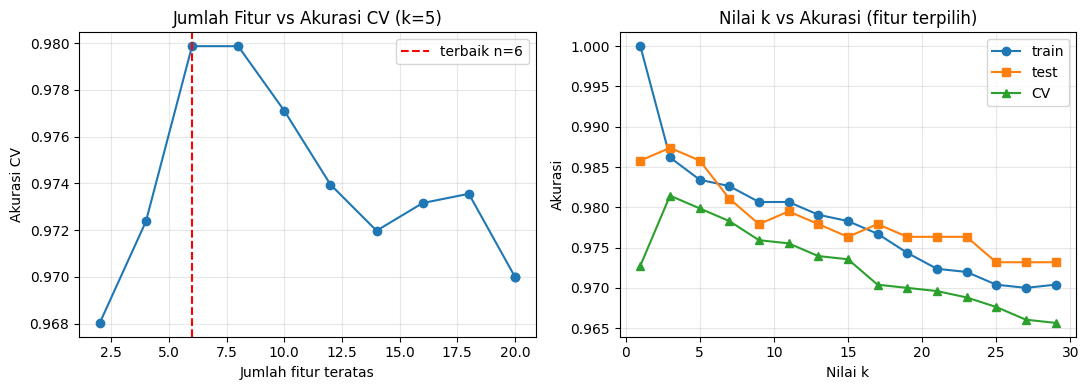

In [5]:
# Grafik: jumlah fitur vs akurasi, dan k vs akurasi
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([r[0] for r in rows], [r[1] for r in rows], marker="o")
ax[0].axvline(best_n, ls="--", c="red",
              label=f"terbaik n={best_n}")
ax[0].set(title="Jumlah Fitur vs Akurasi CV (k=5)",
          xlabel="Jumlah fitur teratas", ylabel="Akurasi CV")
ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot([r[0] for r in res], [r[1] for r in res], marker="o", label="train")
ax[1].plot([r[0] for r in res], [r[2] for r in res], marker="s", label="test")
ax[1].plot([r[0] for r in res], [r[3] for r in res], marker="^", label="CV")
ax[1].set(title="Nilai k vs Akurasi (fitur terpilih)", xlabel="Nilai k",
          ylabel="Akurasi")
ax[1].legend(); ax[1].grid(alpha=.3)
fig.tight_layout()
fig.savefig(OUT / "analisis_fitur_dan_k.png", dpi=110)